In [7]:
import torch.nn as nn
from torchsummary import summary
model = nn.Sequential(
    nn.Linear(2, 2),
    nn.Linear(2, 2),
    nn.Sigmoid()
)
summary(model, (10000000, 2))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1          [-1, 10000000, 2]               6
            Linear-2          [-1, 10000000, 2]               6
           Sigmoid-3          [-1, 10000000, 2]               0
Total params: 12
Trainable params: 12
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 76.29
Forward/backward pass size (MB): 457.76
Params size (MB): 0.00
Estimated Total Size (MB): 534.06
----------------------------------------------------------------


<span style="font-size: 30px;">Gradient Descent without Momentum</span>


In [10]:
import matplotlib.pyplot as plt
import torch
def init_inputs(r_min = -2.0, r_max = 2.0):
    inputs = torch.arange(r_min, r_max + 0.1, 0.1)
    return inputs

In [11]:
init_inputs()

tensor([-2.0000e+00, -1.9000e+00, -1.8000e+00, -1.7000e+00, -1.6000e+00,
        -1.5000e+00, -1.4000e+00, -1.3000e+00, -1.2000e+00, -1.1000e+00,
        -1.0000e+00, -9.0000e-01, -8.0000e-01, -7.0000e-01, -6.0000e-01,
        -5.0000e-01, -4.0000e-01, -3.0000e-01, -2.0000e-01, -1.0000e-01,
         1.1102e-16,  1.0000e-01,  2.0000e-01,  3.0000e-01,  4.0000e-01,
         5.0000e-01,  6.0000e-01,  7.0000e-01,  8.0000e-01,  9.0000e-01,
         1.0000e+00,  1.1000e+00,  1.2000e+00,  1.3000e+00,  1.4000e+00,
         1.5000e+00,  1.6000e+00,  1.7000e+00,  1.8000e+00,  1.9000e+00,
         2.0000e+00])

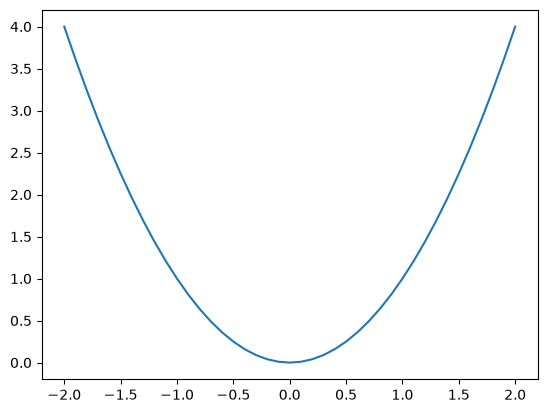

In [12]:
def objective(x):
    return x ** 2
inputs = init_inputs()
results = objective(inputs)
plt.plot(inputs, results)
plt.show()

In [13]:
def derivative(x):
    return 2.0 * x

def sgd(input, num_epochs, learning_rate):
    solutions, scores = [], []
    solution = input
    solution_eval = objective(solution)
    solutions.append(solution)
    scores.append(solution_eval)

    for epoch in range(num_epochs):
        gradient = derivative(solution)

        solution = solution - learning_rate * gradient

        solution_eval = objective(solution)

        solutions.append(solution)
        scores.append(solution_eval)

        print(f'Epoch: %0.2d --f(%0.3f) = %.5f' % (epoch, solution, solution_eval))
    return solutions, scores


In [14]:
input = inputs[0]
input

tensor(-2.)

In [15]:
num_epochs = 20
learning_rate = 0.1
solutions, scores = sgd(input, num_epochs, learning_rate)


Epoch: 00 --f(-1.600) = 2.56000
Epoch: 01 --f(-1.280) = 1.63840
Epoch: 02 --f(-1.024) = 1.04858
Epoch: 03 --f(-0.819) = 0.67109
Epoch: 04 --f(-0.655) = 0.42950
Epoch: 05 --f(-0.524) = 0.27488
Epoch: 06 --f(-0.419) = 0.17592
Epoch: 07 --f(-0.336) = 0.11259
Epoch: 08 --f(-0.268) = 0.07206
Epoch: 09 --f(-0.215) = 0.04612
Epoch: 10 --f(-0.172) = 0.02951
Epoch: 11 --f(-0.137) = 0.01889
Epoch: 12 --f(-0.110) = 0.01209
Epoch: 13 --f(-0.088) = 0.00774
Epoch: 14 --f(-0.070) = 0.00495
Epoch: 15 --f(-0.056) = 0.00317
Epoch: 16 --f(-0.045) = 0.00203
Epoch: 17 --f(-0.036) = 0.00130
Epoch: 18 --f(-0.029) = 0.00083
Epoch: 19 --f(-0.023) = 0.00053


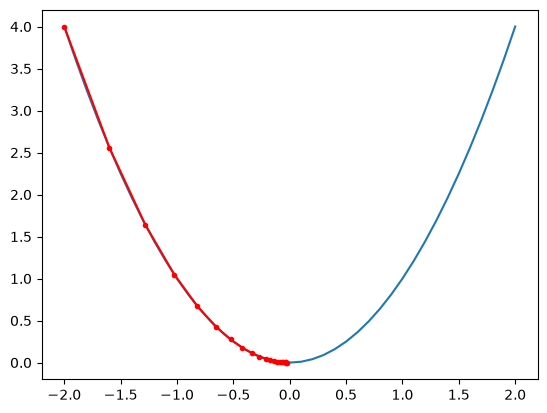

In [16]:
results = objective(inputs)
plt.plot(inputs, results)
plt.plot(solutions, scores, '.-', color = 'red')
plt.show()

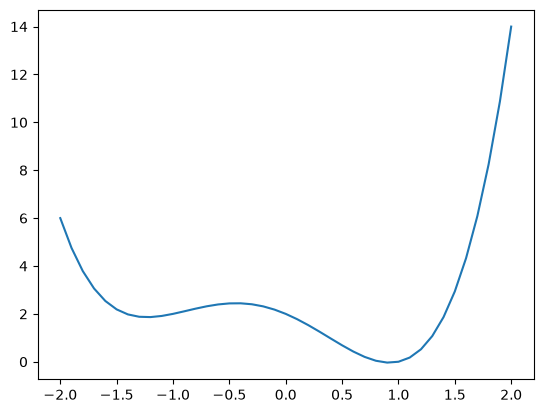

In [ ]:
def objective(x):
    return x ** 4 + x ** 3 - 2 * x ** 2 - 2 * x + 2

inputs = init_inputs()
results = objective(inputs)
plt.plot(inputs, results)
plt.show()

In [21]:
def derivative(x):
    return 4 * x ** 3 + 3 * x ** 2 - 4 * x - 2

num_epochs = 20
learning_rate = 0.1
input = inputs[0]
solutions, scores = sgd(input, num_epochs, learning_rate)

Epoch: 00 --f(-0.600) = 2.39360
Epoch: 01 --f(-0.662) = 2.34977
Epoch: 02 --f(-0.742) = 2.27775
Epoch: 03 --f(-0.840) = 2.17372
Epoch: 04 --f(-0.951) = 2.05123
Epoch: 05 --f(-1.059) = 1.94550
Epoch: 06 --f(-1.144) = 1.88629
Epoch: 07 --f(-1.195) = 1.86667
Epoch: 08 --f(-1.219) = 1.86278
Epoch: 09 --f(-1.228) = 1.86225
Epoch: 10 --f(-1.231) = 1.86219
Epoch: 11 --f(-1.232) = 1.86218
Epoch: 12 --f(-1.232) = 1.86218
Epoch: 13 --f(-1.232) = 1.86218
Epoch: 14 --f(-1.232) = 1.86218
Epoch: 15 --f(-1.232) = 1.86218
Epoch: 16 --f(-1.232) = 1.86218
Epoch: 17 --f(-1.232) = 1.86218
Epoch: 18 --f(-1.232) = 1.86218
Epoch: 19 --f(-1.232) = 1.86218


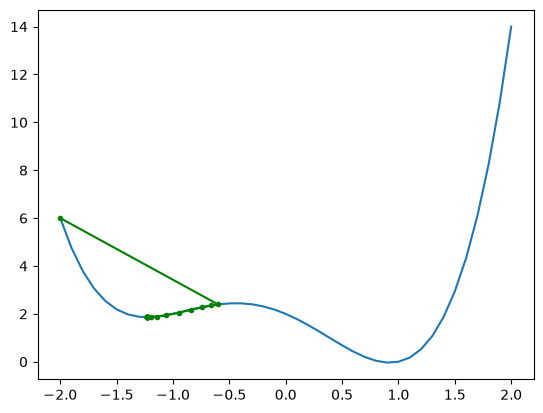

In [22]:
results = objective(inputs)
plt.plot(inputs, results)
plt.plot(solutions, scores, '.-', color = 'green')
plt.show()

<span style = "font-size: 30px"> Momentum </span>

In [36]:
def gradient_descent_momentum(input, num_epochs, learning_rate, momentum):
    solutions, scores = [], []
    solution = input
    change = 0.0
    solution_eval = objective(solution)
    solutions.append(solution)
    scores.append(solution_eval)

    for epoch in range(num_epochs):
        gradient = derivative(solution)
        new_change = momentum * change + learning_rate * gradient

        solution = solution - new_change
        change = new_change
        solution_eval = objective(solution)

        solutions.append(solution)
        scores.append(solution_eval)

        print(f'Epoch: %0.2d --f(%0.3f) = %.5f' % (epoch, solution, solution_eval))
    return solutions, scores
solutions, scores = gradient_descent_momentum(input, num_epochs, learning_rate, 0.8)

Epoch: 00 --f(-0.600) = 2.39360
Epoch: 01 --f(0.458) = 0.80342
Epoch: 02 --f(1.587) = 4.12767
Epoch: 03 --f(0.970) = -0.02355
Epoch: 04 --f(0.417) = 0.91993
Epoch: 05 --f(0.260) = 1.36561
Epoch: 06 --f(0.412) = 0.93599
Epoch: 07 --f(0.819) = 0.02011
Epoch: 08 --f(1.251) = 0.77579
Epoch: 09 --f(1.045) = 0.05894
Epoch: 10 --f(0.714) = 0.17647
Epoch: 11 --f(0.636) = 0.33875
Epoch: 12 --f(0.804) = 0.03617
Epoch: 13 --f(1.058) = 0.08299
Epoch: 14 --f(1.075) = 0.11555
Epoch: 15 --f(0.875) = -0.02500
Epoch: 16 --f(0.767) = 0.08598
Epoch: 17 --f(0.831) = 0.00746
Epoch: 18 --f(0.978) = -0.01892
Epoch: 19 --f(1.025) = 0.02997


[]

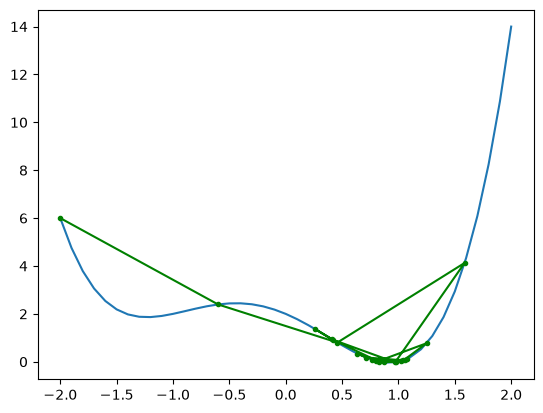

In [37]:
results = objective(inputs)
plt.plot(inputs, results)
plt.plot(solutions, scores, '.-', color = 'green')
plt.plot()